<a href="https://colab.research.google.com/github/jmcelroy01/agentic-ai-for-functional-materials-discovery/blob/main/02_mini_csp_random_search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 2 · A mini crystal structure prediction  (~11 min)

Generate trial packings, relax each one, rank by energy. We start from the paracetamol molecule only and look for
Form I and Form II. Packings come from [PyXtal](https://github.com/MaterSim/PyXtal), energies from MACE-OFF.

In [1]:
# @title 0 · Setup  (run this cell first; ~1-2 min on Colab)
import os, sys
REPO = "https://github.com/fmggggg/agentic-ai-for-functional-materials-discovery"
if "google.colab" in sys.modules:
    if not os.path.exists("/content/csp-tutorial"):
        !git clone -q {REPO} /content/csp-tutorial
    else:
        !git -C /content/csp-tutorial pull -q
    %cd /content/csp-tutorial
    !pip -q install pyxtal mace-torch py3Dmol pymatgen rdkit oxtalign "requests==2.32.4"
import importlib, csp_utils as cu
importlib.reload(cu)   # picks up a fresh copy if Setup is run again
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
print("ready")

/content/csp-tutorial
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ready


## 2.1 Take the molecule (keep its conformer rigid)

In [2]:
form1 = cu.load_cif(cu.DATA / "paracetamol_form_I.cif")
mol = cu.molecule_from_crystal(form1)
print(mol.composition, len(mol), "atoms")

O2 H9 N1 C8 20 atoms


## 2.2 Generate random crystals

Most organic crystals are in one of five space groups: P2₁/c, P1̄, P2₁2₁2₁, C2/c, P2₁.

In [15]:
trial = cu.random_crystal(mol, sg=14, z=8, seed=1)   # P2_1/c, 4 molecules
print("density of this random guess:", round(cu.density(trial), 3), "g/cm3  (experiment: 1.33)")
cu.show(trial, supercell=(2, 2, 2))

density of this random guess: 1.095 g/cm3  (experiment: 1.33)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

30 structures in 2.4 s


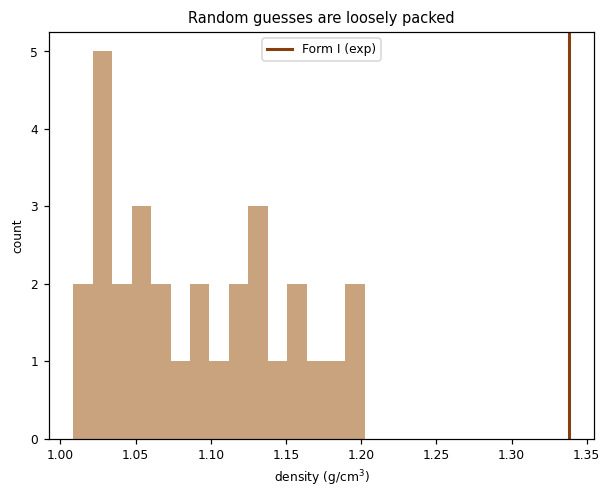

In [16]:
import time
plan = [(14, 4), (2, 2), (19, 4), (4, 2), (61, 8)]
t0 = time.time()
raw = [cu.random_crystal(mol, sg, z, seed=i) for i, (sg, z) in enumerate(plan * 6)]
print(f"{len(raw)} structures in {time.time()-t0:.1f} s")
plt.hist([cu.density(a) for a in raw], bins=15, color="#C9A27E")
plt.axvline(cu.density(form1), color="#893F0D", lw=2, label="Form I (exp)")
plt.xlabel("density (g/cm$^3$)"); plt.ylabel("count"); plt.legend(); plt.title("Random guesses are loosely packed");

Try other space groups and starting volumes. Each change builds one new random crystal.

In [5]:
from ipywidgets import interact, Dropdown, FloatSlider, IntSlider

groups = {"P2₁/c, Z=4": (14, 4), "P1̄, Z=2": (2, 2), "P2₁2₁2₁, Z=4": (19, 4), "P2₁, Z=2": (4, 2), "Pbca, Z=8": (61, 8)}

@interact(space_group=Dropdown(options=list(groups)),
          volume=FloatSlider(value=0.8, min=0.7, max=1.2, step=0.05, continuous_update=False),
          seed=IntSlider(value=0, min=0, max=20, continuous_update=False))
def build(space_group, volume, seed):
    sg, z = groups[space_group]
    at = cu.random_crystal(mol, sg, z, seed=seed, factor=volume)
    cu.draw_cell(at, title=f"{space_group}: density {cu.density(at):.2f} g/cm$^3$  (Form I: 1.33)")
    plt.show()

interactive(children=(Dropdown(description='space_group', options=('P2₁/c, Z=4', 'P1̄, Z=2', 'P2₁2₁2₁, Z=4', '…

## 2.3 Relax one of them

Atoms and cell both move. We stop after 100 steps, so it is not fully converged.

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
relaxed in 67 s; energy -1354440 kJ/mol per molecule


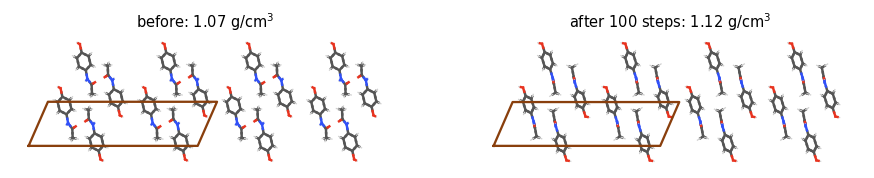

In [6]:
t0 = time.time()
before = raw[0]
after = cu.relax(before, steps=100)
print(f"relaxed in {time.time() - t0:.0f} s; energy {cu.energy_per_molecule(after):.0f} kJ/mol per molecule")
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
lim = cu.draw_cell(before, axs[0], title=f"before: {cu.density(before):.2f} g/cm$^3$")
cu.draw_cell(after, axs[1], title=f"after 100 steps: {cu.density(after):.2f} g/cm$^3$", limits=lim)
plt.show()

> **Question.** How long did one relaxation take? A real CSP study relaxes 10⁴–10⁵ structures per molecule. How long would that take?

## 2.4 200 random structures, run beforehand

We ran the same random search before the school: 200 structures, each relaxed like the one above.
Stars: the two experimental forms, relaxed with MACE-OFF. Energies are relative to Form I.

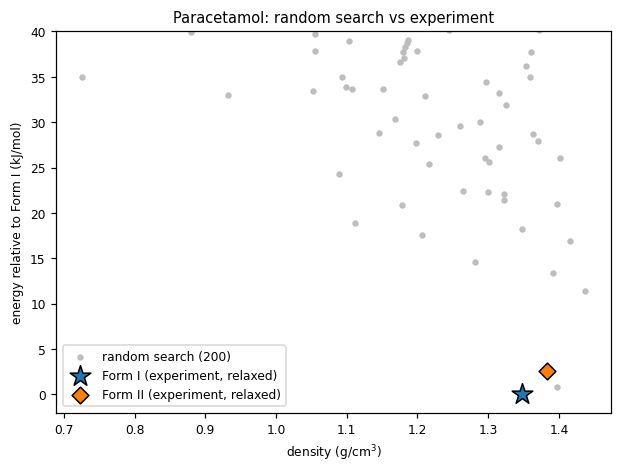

In [7]:
from ase.io import read
L = cu.load_landscape("landscape_random")
e_gas = cu.gas_phase_energy()
exp = {}
for n in ("I", "II"):
    at = read(cu.DATA / f"paracetamol_form_{n}_relaxed.extxyz")
    exp[n] = (cu.density(at), cu.energy_per_molecule(at) - e_gas)
E0 = exp["I"][1]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(L.density, L.lattice_energy_kjmol - E0, s=10, c="#BDBDBD", label=f"random search ({len(L)})")
for n, mk, sz in [("I", "*", 200), ("II", "D", 60)]:
    ax.scatter(exp[n][0], exp[n][1] - E0, s=sz, marker=mk, edgecolor="k", zorder=5, label=f"Form {n} (experiment, relaxed)")
ax.set_xlabel("density (g/cm$^3$)"); ax.set_ylabel("energy relative to Form I (kJ/mol)"); ax.set_ylim(-2, 40)
ax.legend(); ax.set_title("Paracetamol: random search vs experiment");

In [8]:
rel = (L.lattice_energy_kjmol - E0).sort_values()
print("random structures matching Form I or II:", int(L.rms_form_I.notna().sum() + L.rms_form_II.notna().sum()), "of", len(L))
print("lowest random structure:", round(rel.iloc[0], 1), "kJ/mol above Form I")
print("random structures within 5 kJ/mol of Form I:", (rel < 5).sum())

random structures matching Form I or II: 0 of 200
lowest random structure: 0.8 kJ/mol above Form I
random structures within 5 kJ/mol of Form I: 1


## 2.5 Same molecule, a generative model (~1 min)

None of the 200 random structures is Form I or Form II. Now take 100 crystal structures of paracetamol sampled from Clari-H (Z = 4 or 8), taken straight from the model.
We score them against both forms with OXtalign: a cluster of 15 molecules is overlaid on the reference
and the matching molecules are counted. Clari was trained on the CSD, which contains both forms.

In [9]:
P = cu.para_clari_table()
forms = {n: cu.to_pmg(cu.load_cif(cu.DATA / f"paracetamol_form_{n}.cif")) for n in ("I", "II")}
t0 = time.time()
for n, ref in forms.items():
    S = cu.oxtalign_scores(P.name, ref, structure=cu.para_clari_structure)
    P[f"form {n} (of 15)"] = P.name.map(S.set_index("sample")["molecules matched (of 15)"])
print(f"scored in {time.time() - t0:.0f} s")
print("match Form I (15/15):", (P["form I (of 15)"] == 15).sum(), "| match Form II:", (P["form II (of 15)"] == 15).sum())
P.sort_values(["form I (of 15)", "form II (of 15)"], ascending=False).head(5)

scored in 27 s
match Form I (15/15): 1 | match Form II: 0


,name,Z,density_raw,intact,density,rel_energy_kjmol,form I (of 15),form II (of 15)
5,Z4_s000010,4,1.3454,True,1.4106,2.07,15,1
57,Z4_s000098,4,1.3144,True,1.3577,10.84,7,1
87,Z8_s000022,8,1.3569,True,1.3691,16.77,3,4
16,Z4_s000031,4,1.3637,True,1.4566,14.60,3,2
76,Z8_s000009,8,1.3135,True,1.3220,15.45,3,2


Z4_s000010 relaxed in 42 s; energy relative to Form I: 1.3 kJ/mol


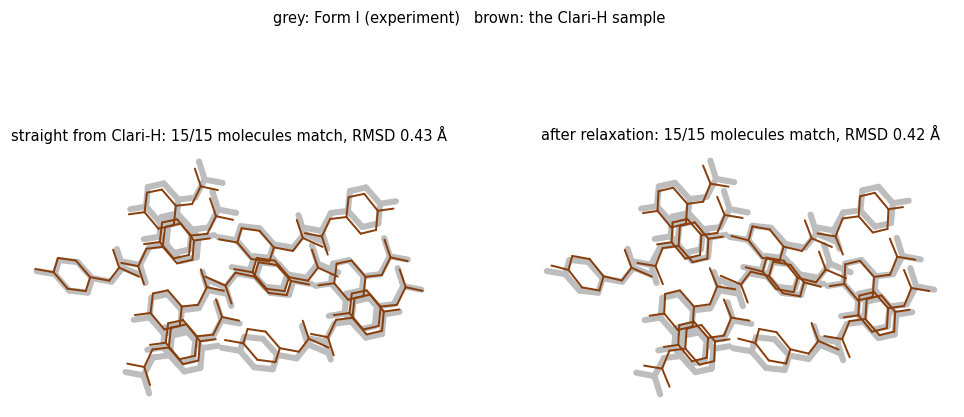

In [10]:
best = P.sort_values("form I (of 15)", ascending=False).name.iloc[0]
raw = cu.para_clari_structure(best)
t0 = time.time()
r = cu.relax(cu.to_ase(raw), fmax=0.05, steps=100, symmetry=False)
print(best, f"relaxed in {time.time() - t0:.0f} s;",
      "energy relative to Form I:", round(cu.energy_per_molecule(r) - e_gas - E0, 1), "kJ/mol")
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
cu.draw_overlay(forms["I"], raw, axs[0], title="straight from Clari-H")
cu.draw_overlay(forms["I"], cu.to_pmg(r), axs[1], title="after relaxation")
fig.suptitle("grey: Form I (experiment)   brown: the Clari-H sample")
plt.show()

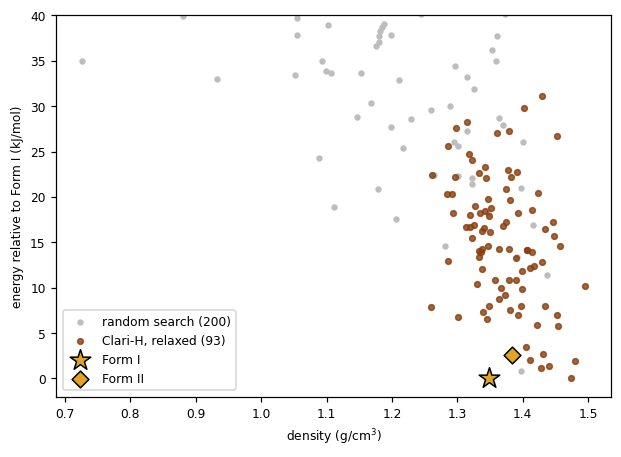

In [11]:
C = P[P.intact]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(L.density, L.lattice_energy_kjmol - E0, s=10, c="#BDBDBD", label=f"random search ({len(L)})")
ax.scatter(C.density, C.rel_energy_kjmol, s=14, c="#893F0D", alpha=.8, label=f"Clari-H, relaxed ({len(C)})")
for n, mk, sz in [("I", "*", 200), ("II", "D", 60)]:
    ax.scatter(exp[n][0], exp[n][1] - E0, s=sz, marker=mk, c="#E0A526", edgecolor="k", zorder=5, label=f"Form {n}")
ax.set_xlabel("density (g/cm$^3$)"); ax.set_ylabel("energy relative to Form I (kJ/mol)"); ax.set_ylim(-2, 40)
ax.legend(fontsize=8);

> **Question.** Clari-H found Form I among 100 samples. Is that a fair test for a model trained on the CSD, which contains paracetamol?